# Comparison Model 1: Linear GCN (LGCN)
## Prostate Cancer Detection 

| Model | Architecture | Role |
|---|---|---|
| Hybrid | EfficientNet-B4 + GAT + GCN | Main proposed model |
| **This notebook** | EfficientNet-B4 + Linear GCN | Comparison 1 |


In [ ]:
# Resolve the repository root so this notebook runs from a clean clone.
import os
REPO_ROOT = os.getcwd()
while not os.path.exists(os.path.join(REPO_ROOT, 'config.py')):
    parent = os.path.dirname(REPO_ROOT)
    if parent == REPO_ROOT:
        raise RuntimeError('config.py not found - run this notebook from inside the repository')
    REPO_ROOT = parent
print('REPO_ROOT:', REPO_ROOT)


In [1]:
import torch, torch_geometric, timm, cv2, numpy, sklearn, PIL
from torch_geometric.nn import GCNConv, global_mean_pool, global_max_pool
from torch_geometric.data import Data, Batch
print(f'PyTorch : {torch.__version__}')
print(f'CUDA    : {torch.version.cuda}')
print(f'PyG     : {torch_geometric.__version__}')
print(f'GPU     : {torch.cuda.get_device_name(0)}')
print('All imports OK')

PyTorch : 2.5.1+cu121
CUDA    : 12.1
PyG     : 2.5.3
GPU     : NVIDIA GeForce RTX 3060
All imports OK


## Cell 1  Install Dependencies

In [2]:
# CELL 1 — Install Dependencies
import subprocess, sys

def pip(pkg):
    subprocess.check_call([sys.executable, '-m', 'pip', 'install'] + pkg.split() + ['-q'])

# Step 1: Core packages (always works)
pip('torch torchvision --index-url https://download.pytorch.org/whl/cu121')
pip('torch-geometric')
pip('scikit-learn scikit-image')
pip('matplotlib seaborn tqdm Pillow numpy pandas torchinfo')

# Step 2: torch-scatter and torch-sparse (Windows-safe install)
import torch
tv = torch.__version__.split('+')[0]          # e.g. '2.3.0'
cu = 'cu121'
url = f'https://data.pyg.org/whl/torch-{tv}+{cu}.html'

try:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install',
                           'torch-scatter', 'torch-sparse',
                           '-f', url, '-q'])
    print('torch-scatter and torch-sparse installed successfully.')
except Exception as e:
    print(f'PyG extras failed ({e}). Trying CPU-only fallback...')
    try:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install',
                               'torch-scatter', 'torch-sparse',
                               '-f', 'https://data.pyg.org/whl/torch-2.3.0+cpu.html', '-q'])
        print('CPU fallback installed.')
    except:
        print('Skipping torch-scatter/sparse — torch-geometric will use pure Python fallback.')

print()
print('=' * 55)
print('  All packages installed.')
print('  RESTART KERNEL now, then run from Cell 2.')
print('=' * 55)

torch-scatter and torch-sparse installed successfully.

  All packages installed.
  RESTART KERNEL now, then run from Cell 2.


## Cell 2 — Imports and Config

In [3]:
# ═══════════════════════════════════════════════════════════════════
# CELL 2 — Imports and Config  (LOCAL PC — matched to Hybrid retrain)
# ═══════════════════════════════════════════════════════════════════
import os, random, warnings, pickle, time, json, shutil, sys, platform
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from tqdm import tqdm
from PIL import Image
import cv2

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
import torchvision.transforms as T

from torch_geometric.data import Data, Batch
from torch_geometric.nn import GCNConv, global_mean_pool, global_max_pool

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    roc_auc_score, confusion_matrix, classification_report,
    matthews_corrcoef, roc_curve, precision_recall_curve, auc
)
from sklearn.neighbors import kneighbors_graph
warnings.filterwarnings('ignore')

def denormalize(img_tensor):
    """Convert normalized tensor back to [0,1] RGB for display."""
    mean = np.array([0.485, 0.456, 0.406])
    std  = np.array([0.229, 0.224, 0.225])
    img  = img_tensor.cpu().numpy().transpose(1, 2, 0)
    return np.clip(img * std + mean, 0, 1)

# ── LOCAL PATH SETUP (matched to Hybrid retrain) ──
WORK_DIR   = os.path.join(REPO_ROOT, 'runs', 'lgcn')
DATA_ROOT  = REPO_ROOT
os.makedirs(WORK_DIR, exist_ok=True)
os.makedirs(os.path.join(WORK_DIR, 'checkpoints_backup'), exist_ok=True)

CONFIG = {
    'data_dir'         : os.path.join(DATA_ROOT, 'dataset'),
    'output_dir'       : WORK_DIR,
    'graph_cache_path' : os.path.join(DATA_ROOT, 'cache', 'lgcn_graph_cache.pkl'),
    'model_save_path'  : os.path.join(WORK_DIR, 'best_lgcn_model.pth'),
    'backup_dir'       : os.path.join(WORK_DIR, 'checkpoints_backup'),

    'img_size'         : 224,
    'patch_size'       : 32,
    'k_neighbors'      : 6,

    'lgcn_hidden_dim'  : 256,
    'lgcn_layers'      : 3,
    'lgcn_dropout'     : 0.4,
    'fusion_dim'       : 512,
    'num_classes'      : 2,

    'batch_size'       : 32,
    'num_epochs'       : 80,
    'lr_backbone'      : 1e-4,
    'lr_lgcn'          : 3e-4,
    'weight_decay'     : 1e-4,
    'patience'         : 15,
    'focal_gamma'      : 2.0,
    'focal_alpha'      : 0.75,
    'seed'             : 42,
    'train_split'      : 0.70,
    'val_split'        : 0.15,
    'test_split'       : 0.15,
    'num_workers'      : 0,
    'use_amp'          : False,
    'tta_n'            : 5,
}

def set_seed(s):
    random.seed(s); np.random.seed(s)
    torch.manual_seed(s); torch.cuda.manual_seed_all(s)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark     = False

SEED = CONFIG['seed']
set_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print('=' * 60)
print('  COMPARISON MODEL 1: LINEAR GCN (LGCN) — LOCAL RETRAIN')
print('  MATCHED to Hybrid retrain protocol')
print('=' * 60)
print(f'  Device       : {DEVICE}')
if torch.cuda.is_available():
    print(f'  GPU          : {torch.cuda.get_device_name(0)}')
    print(f'  VRAM         : {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB')
print(f'  PyTorch      : {torch.__version__}')
print(f'  CUDA         : {torch.version.cuda}')
print(f'  Work dir     : {WORK_DIR}')
print(f'  Graph cache  : {CONFIG["graph_cache_path"]}')
print(f'  Model output : {CONFIG["model_save_path"]}')
print(f'  Epochs       : {CONFIG["num_epochs"]}  |  Patience : {CONFIG["patience"]}')
print(f'  Batch        : {CONFIG["batch_size"]}  |  Seed : {SEED}')
print(f'  Loss         : Focal (gamma={CONFIG["focal_gamma"]}, alpha={CONFIG["focal_alpha"]})')
print('=' * 60)


  COMPARISON MODEL 1: LINEAR GCN (LGCN) — LOCAL RETRAIN
  MATCHED to Hybrid retrain protocol
  Device       : cuda
  GPU          : NVIDIA GeForce RTX 3060
  VRAM         : 12.9 GB
  PyTorch      : 2.5.1+cu121
  CUDA         : 12.1
  Work dir     : <repo>/results\Retrain_LGCN
  Graph cache  : <repo>/cache\lgcn_graph_cache.pkl
  Model output : <repo>/results\Retrain_LGCN\best_lgcn_model.pth
  Epochs       : 80  |  Patience : 15
  Batch        : 32  |  Seed : 42
  Loss         : Focal (gamma=2.0, alpha=0.75)


## Cell 3 — Dataset and Graph Construction

In [4]:
# ═══════════════════════════════════════════════════════════════════
# CELL 3 — Dataset, Graph Construction & Augmentation
# MATCHED to Hybrid: TrivialAugment + ColorJitter + RandomErasing
#                    + MixUp + WeightedRandomSampler + TTA
# ═══════════════════════════════════════════════════════════════════

def build_patch_graph(img_tensor, patch_size=32, k=6):
    C, H, W = img_tensor.shape
    ph = pw = patch_size
    n_h = H // ph; n_w = W // pw
    patches, positions = [], []
    for i in range(n_h):
        for j in range(n_w):
            patch = img_tensor[:, i*ph:(i+1)*ph, j*pw:(j+1)*pw]
            feat  = patch.reshape(-1)
            feat_agg = torch.stack([
                feat.mean(), feat.std(), feat.max(), feat.min(),
                (feat > feat.mean()).float().mean(), feat.median(),
                ((patch[0]-patch[1]).abs()).mean() if C>=2 else torch.tensor(0.),
                ((patch[1]-patch[2]).abs()).mean() if C>=3 else torch.tensor(0.),
            ])
            patches.append(feat_agg); positions.append([i, j])
    x  = torch.stack(patches)
    pos = np.array(positions, dtype=np.float32)
    A  = kneighbors_graph(pos, n_neighbors=k, mode='connectivity', include_self=False)
    src, dst = A.nonzero()
    edge_index = torch.tensor(np.stack([src, dst], axis=0), dtype=torch.long)
    return Data(x=x, edge_index=edge_index)

# ── MATCHED: Stronger augmentation (same as Hybrid) ────────────
TRAIN_TF = T.Compose([
    T.Resize((CONFIG['img_size'], CONFIG['img_size'])),
    T.RandomHorizontalFlip(p=0.5),
    T.RandomVerticalFlip(p=0.3),
    T.RandomRotation(degrees=15),
    T.TrivialAugmentWide(),                         # MATCHED from Hybrid
    T.ColorJitter(brightness=0.2, contrast=0.2,
                  saturation=0.1, hue=0.05),        # MATCHED from Hybrid
    T.ToTensor(),
    T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    T.RandomErasing(p=0.25, scale=(0.02, 0.1)),     # MATCHED from Hybrid
])
EVAL_TF = T.Compose([
    T.Resize((CONFIG['img_size'], CONFIG['img_size'])),
    T.ToTensor(),
    T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

# ── MATCHED: TTA transforms (5 views at inference, same as Hybrid) ──
tta_transforms = [
    T.Compose([
        T.Resize((CONFIG['img_size'], CONFIG['img_size'])),
        T.ToTensor(),
        T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    ]),
    T.Compose([
        T.Resize((CONFIG['img_size'], CONFIG['img_size'])),
        T.RandomHorizontalFlip(p=1.0),
        T.ToTensor(),
        T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    ]),
    T.Compose([
        T.Resize((int(CONFIG['img_size']*1.1), int(CONFIG['img_size']*1.1))),
        T.CenterCrop(CONFIG['img_size']),
        T.ToTensor(),
        T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    ]),
    T.Compose([
        T.Resize((CONFIG['img_size'], CONFIG['img_size'])),
        T.RandomRotation(degrees=(90, 90)),
        T.ToTensor(),
        T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    ]),
    T.Compose([
        T.Resize((CONFIG['img_size'], CONFIG['img_size'])),
        T.RandomRotation(degrees=(180, 180)),
        T.ToTensor(),
        T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    ]),
]

# ── Dataset class ───────────────────────────────────────────
class ProstateGraphDataset(Dataset):
    def __init__(self, file_list, labels, transform):
        self.file_list = file_list
        self.labels    = labels
        self.transform = transform
        self.graph_cache = {}
        if os.path.exists(CONFIG['graph_cache_path']):
            with open(CONFIG['graph_cache_path'], 'rb') as f:
                self.graph_cache = pickle.load(f)
            print(f'  Loaded {len(self.graph_cache)} cached graphs')

    def __len__(self): return len(self.file_list)

    def __getitem__(self, idx):
        path  = self.file_list[idx]
        label = self.labels[idx]
        img   = Image.open(path).convert('RGB')
        img_t = self.transform(img)
        if path in self.graph_cache:
            graph = self.graph_cache[path]
        else:
            graph = build_patch_graph(EVAL_TF(img), CONFIG['patch_size'], CONFIG['k_neighbors'])
            self.graph_cache[path] = graph
        return img_t, graph, torch.tensor(label, dtype=torch.long)

# ── MATCHED: MixUp (same as Hybrid) ────────────────────────
def mixup_data(x, y, alpha=0.2):
    lam = np.random.beta(alpha, alpha) if alpha > 0 else 1
    idx = torch.randperm(x.size(0), device=x.device)
    mixed = lam * x + (1 - lam) * x[idx]
    return mixed, y, y[idx], lam

def mixup_criterion(criterion, pred, y_a, y_b, lam):
    return lam * criterion(pred, y_a) + (1 - lam) * criterion(pred, y_b)

def collate_fn(batch):
    imgs, graphs, labels = zip(*batch)
    return torch.stack(imgs), Batch.from_data_list(list(graphs)), torch.stack(labels)

# ── Build file lists ────────────────────────────────────────
data_dir = Path(CONFIG['data_dir'])
IMG_EXTS = {'.jpg', '.jpeg', '.png', '.bmp'}
all_paths, all_labels = [], []
for label_idx, cls in enumerate(['Benign', 'Malignant']):
    class_dir = data_dir / cls
    if not class_dir.exists():
        for alt in [cls.capitalize(), cls.upper()]:
            if (data_dir / alt).exists(): class_dir = data_dir / alt; break
    files = [p for p in class_dir.iterdir() if p.suffix.lower() in IMG_EXTS]
    all_paths.extend([str(p) for p in files])
    all_labels.extend([label_idx]*len(files))
    print(f'  {cls:12s}: {len(files):5d} images')
all_paths  = np.array(all_paths)
all_labels = np.array(all_labels)
print(f'  Total: {len(all_paths)} images')

idx = np.arange(len(all_paths))
train_idx, temp_idx = train_test_split(idx, test_size=0.30, stratify=all_labels, random_state=42)
val_idx,  test_idx  = train_test_split(temp_idx, test_size=0.50, stratify=all_labels[temp_idx], random_state=42)

train_ds = ProstateGraphDataset(all_paths[train_idx], all_labels[train_idx], TRAIN_TF)
val_ds   = ProstateGraphDataset(all_paths[val_idx],   all_labels[val_idx],   EVAL_TF)
test_ds  = ProstateGraphDataset(all_paths[test_idx],  all_labels[test_idx],  EVAL_TF)

# ── MATCHED: WeightedRandomSampler (same as Hybrid) ────────
train_labels_arr = all_labels[train_idx]
class_counts = np.bincount(train_labels_arr)
sample_weights = 1.0 / class_counts[train_labels_arr]
sampler = WeightedRandomSampler(sample_weights, len(sample_weights), replacement=True)

train_loader = DataLoader(train_ds, CONFIG['batch_size'], sampler=sampler,
                          num_workers=0, collate_fn=collate_fn, pin_memory=True)
val_loader   = DataLoader(val_ds,   CONFIG['batch_size'], shuffle=False,
                          num_workers=0, collate_fn=collate_fn, pin_memory=True)
test_loader  = DataLoader(test_ds,  CONFIG['batch_size'], shuffle=False,
                          num_workers=0, collate_fn=collate_fn, pin_memory=True)

print(f'  Train:{len(train_idx)} | Val:{len(val_idx)} | Test:{len(test_idx)}')
print(f'  Augmentation: STRONG (TrivialAugment + ColorJitter + RandomErasing)')
print(f'  MixUp: Enabled (alpha=0.2, 50% of batches)')
print(f'  TTA: {CONFIG["tta_n"]} views at inference')
print(f'  Sampler: WeightedRandomSampler (balanced classes)')


  Benign      :  3000 images
  Malignant   :  3002 images
  Total: 6002 images
  Loaded 6002 cached graphs
  Loaded 6002 cached graphs
  Loaded 6002 cached graphs
  Train:4201 | Val:900 | Test:901
  Augmentation: STRONG (TrivialAugment + ColorJitter + RandomErasing)
  MixUp: Enabled (alpha=0.2, 50% of batches)
  TTA: 5 views at inference
  Sampler: WeightedRandomSampler (balanced classes)


## Cell 4 — Build Graph Cache 

In [5]:
# CELL 4 — Build Graph Cache
# Run ONCE only. Skip on future runs if lgcn_graph_cache.pkl already exists.

FORCE_REBUILD = True

if os.path.exists(CONFIG['graph_cache_path']) and not FORCE_REBUILD:
    print(f'Cache exists. Skipping. Set FORCE_REBUILD=True to rebuild.')
else:
    print(f'Building graphs for {len(all_paths)} images...')
    graph_cache = {}
    for path in tqdm(all_paths, desc='Building graphs'):
        try:
            img   = Image.open(path).convert('RGB')
            graph_cache[path] = build_patch_graph(EVAL_TF(img), CONFIG['patch_size'], CONFIG['k_neighbors'])
        except: pass
    with open(CONFIG['graph_cache_path'], 'wb') as f:
        pickle.dump(graph_cache, f, protocol=4)
    for ds in [train_ds, val_ds, test_ds]:
        ds.graph_cache = graph_cache
    print(f'Done. {len(graph_cache)} graphs saved to: {CONFIG["graph_cache_path"]}')

Building graphs for 6002 images...


Building graphs: 100%|██████████| 6002/6002 [01:21<00:00, 73.21it/s]


Done. 6002 graphs saved to: <repo>/cache\lgcn_graph_cache.pkl


## Cell 5 — Linear GCN Model Architecture

In [6]:
# ═══════════════════════════════════════════════════════════════════
# CELL 5 — Linear GCN Model Architecture (TUNED for higher accuracy)
#
# Image  -> EfficientNet-B4 -> AvgPool -> 512-dim
# Graph  -> Linear Proj -> LGCN x3 (NO ReLU, + residual) -> MeanPool+MaxPool -> 256-dim
# Fusion -> Concat[512+256] -> MLP -> 2 classes
#
# KEY DIFFERENCE from Hybrid:
#   Hybrid: GCNConv -> ReLU -> GCNConv -> ReLU  (non-linear)
#   LGCN  : GCNConv -> GCNConv -> GCNConv       (linear, NO ReLU between layers)
#
# TUNING CHANGES (v3):
#   1. Unfreeze from block 5 instead of 6 → more fine-tuning capacity
#   2. Residual connections in LGCN → prevents gradient degradation
#   3. Larger fusion MLP → 512→256→128 for better feature mixing
#   4. LeakyReLU in fusion MLP → avoids dead neurons
# ═══════════════════════════════════════════════════════════════════

class LinearGCNLayer(nn.Module):
    """One linear GCN step: A_hat * X * W — NO activation between layers."""
    def __init__(self, in_dim, out_dim, dropout=0.0):
        super().__init__()
        self.gcn     = GCNConv(in_dim, out_dim, add_self_loops=True, normalize=True)
        self.bn      = nn.BatchNorm1d(out_dim)
        self.dropout = nn.Dropout(dropout)
    def forward(self, x, edge_index):
        return self.dropout(self.bn(self.gcn(x, edge_index)))  # NO ReLU

class LGCNBranch(nn.Module):
    """Linear GCN branch with residual connections for stability."""
    def __init__(self, node_feat_dim=8, hidden_dim=256, K=3, dropout=0.3):
        super().__init__()
        self.input_proj = nn.Sequential(
            nn.Linear(node_feat_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim)
        )
        self.layers = nn.ModuleList([
            LinearGCNLayer(hidden_dim, hidden_dim, dropout) for _ in range(K)
        ])
        self.out_proj = nn.Linear(hidden_dim * 2, hidden_dim)

    def forward(self, x, edge_index, batch):
        x = self.input_proj(x)
        for layer in self.layers:
            x = layer(x, edge_index) + x  # RESIDUAL connection (TUNING)
        g = torch.cat([global_mean_pool(x, batch),
                       global_max_pool(x, batch)], dim=1)
        return self.out_proj(g)

class ProstateLGCN(nn.Module):
    def __init__(self, config):
        super().__init__()
        from torchvision.models import efficientnet_b4, EfficientNet_B4_Weights
        backbone = efficientnet_b4(weights=EfficientNet_B4_Weights.IMAGENET1K_V1)
        self.cnn_features = backbone.features
        self.cnn_pool     = nn.AdaptiveAvgPool2d(1)

        # TUNED: unfreeze from block 5 (was 6) → more fine-tuning
        for i, layer in enumerate(self.cnn_features):
            if i < 5:  # freeze blocks 0-4, fine-tune 5-8
                for p in layer.parameters():
                    p.requires_grad = False

        self.cnn_proj = nn.Sequential(
            nn.Linear(1792, config['fusion_dim']),
            nn.BatchNorm1d(config['fusion_dim']),
            nn.SiLU(),
            nn.Dropout(0.3),
        )

        self.lgcn = LGCNBranch(
            8, config['lgcn_hidden_dim'],
            config['lgcn_layers'],
            config['lgcn_dropout']
        )

        total_dim = config['fusion_dim'] + config['lgcn_hidden_dim']

        # TUNED: deeper fusion MLP with LeakyReLU
        self.fusion_mlp = nn.Sequential(
            nn.Linear(total_dim, 512),
            nn.BatchNorm1d(512),
            nn.LeakyReLU(0.1),
            nn.Dropout(0.4),
            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.LeakyReLU(0.1),
            nn.Dropout(0.3),
            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.LeakyReLU(0.1),
            nn.Dropout(0.2),
            nn.Linear(128, config['num_classes']),
        )

        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)

    def forward(self, img, graph_batch):
        cnn  = self.cnn_proj(self.cnn_pool(self.cnn_features(img)).flatten(1))
        lgcn = self.lgcn(graph_batch.x, graph_batch.edge_index, graph_batch.batch)
        return self.fusion_mlp(torch.cat([cnn, lgcn], dim=1))


model = ProstateLGCN(CONFIG).to(DEVICE)
total_p = sum(p.numel() for p in model.parameters())
train_p = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Total params: {total_p:,} | Trainable: {train_p:,}')
print(f'LGCN K={CONFIG["lgcn_layers"]} layers (NO ReLU, + residual)')
print(f'CNN->512 | Graph->256 | Fused->768 | MLP: 768→512→256→128→2')
print(f'CNN freeze: blocks 0-4 | Fine-tune: blocks 5-8')


Total params: 19,360,714 | Trainable: 18,031,454
LGCN K=3 layers (NO ReLU, + residual)
CNN->512 | Graph->256 | Fused->768 | MLP: 768→512→256→128→2
CNN freeze: blocks 0-4 | Fine-tune: blocks 5-8


## Cell 6 — Training

In [7]:
# ═══════════════════════════════════════════════════════════════════
# CELL 6 — Training Loop (MATCHED to Hybrid GAT+GCN)
# Changes from original LGCN:
#   1. Focal Loss (gamma=2, alpha=0.75) replaces CE+LabelSmoothing
#   2. MixUp augmentation (50% of batches)
#   3. Clean train metrics (eval mode, no aug) for fair comparison
#   4. TTA evaluation on test set after training
#   5. 80 epochs, patience=15, CosineAnnealingWarmRestarts
# ═══════════════════════════════════════════════════════════════════

# ── Focal Loss (MATCHED from Hybrid) ────────────────────────
class FocalLoss(nn.Module):
    """
    Focal Loss = -alpha * (1-pt)^gamma * log(pt)
    gamma=2 : strong focus on misclassified samples
    alpha=0.75: slight up-weight for malignant class
    """
    def __init__(self, gamma=2.0, alpha=0.75, reduction='mean'):
        super().__init__()
        self.gamma     = gamma
        self.alpha     = alpha
        self.reduction = reduction

    def forward(self, inputs, targets):
        ce_loss = F.cross_entropy(inputs, targets, reduction='none')
        pt      = torch.exp(-ce_loss)
        alpha_t = torch.where(targets == 1,
                              torch.tensor(self.alpha,   device=inputs.device),
                              torch.tensor(1-self.alpha, device=inputs.device))
        focal   = alpha_t * (1 - pt) ** self.gamma * ce_loss
        return focal.mean() if self.reduction == 'mean' else focal.sum()


# ── Optimizer (differential LR, same as Hybrid) ─────────────
optimizer = torch.optim.AdamW([
    {'params': model.cnn_features.parameters(), 'lr': CONFIG['lr_backbone']},
    {'params': model.cnn_proj.parameters(),     'lr': CONFIG['lr_lgcn']},
    {'params': model.lgcn.parameters(),         'lr': CONFIG['lr_lgcn']},
    {'params': model.fusion_mlp.parameters(),   'lr': CONFIG['lr_lgcn']},
], weight_decay=CONFIG['weight_decay'])

# ── Scheduler (MATCHED: T0=10, T_mult=2, same as Hybrid) ────
scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(
    optimizer, T_0=10, T_mult=2, eta_min=1e-6
)

# ── Loss: Focal Loss (MATCHED from Hybrid) ──────────────────
criterion = FocalLoss(
    gamma=CONFIG['focal_gamma'],
    alpha=CONFIG['focal_alpha']
)

scaler = torch.cuda.amp.GradScaler(enabled=False)


# ── Training function (with MixUp, matched from Hybrid) ─────
def train_epoch(model, loader, optimizer, criterion, use_mixup=True):
    model.train()
    tot_loss = correct = total = 0
    for imgs, graphs, labels in loader:
        imgs   = imgs.to(DEVICE)
        graphs = graphs.to(DEVICE)
        labels = labels.to(DEVICE)

        # MixUp augmentation (50% of batches, same as Hybrid)
        if use_mixup and random.random() < 0.5:
            imgs, y_a, y_b, lam = mixup_data(imgs, labels, alpha=0.2)
            logits = model(imgs, graphs)
            loss   = mixup_criterion(criterion, logits, y_a, y_b, lam)
        else:
            logits = model(imgs, graphs)
            loss   = criterion(logits, labels)

        if torch.isnan(loss):
            continue

        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        tot_loss += loss.item()
        total    += labels.size(0)
        correct  += (logits.argmax(1) == labels).sum().item()

    return tot_loss / len(loader), correct / total


# ── Evaluation function (fp32, NaN-safe, same as Hybrid) ────
@torch.no_grad()
def evaluate(model, loader, criterion):
    """Pure fp32 evaluation — no AMP, no NaN."""
    model.eval()
    tot_loss = correct = total = 0
    all_probs, all_labels = [], []

    for imgs, graphs, labels in loader:
        imgs   = imgs.to(DEVICE)
        graphs = graphs.to(DEVICE)
        labels = labels.to(DEVICE)

        logits = model(imgs, graphs)
        loss   = criterion(logits, labels)

        probs = torch.softmax(logits, dim=1)[:, 1]
        probs = torch.nan_to_num(probs, nan=0.5, posinf=1.0, neginf=0.0)

        all_probs.extend(probs.cpu().numpy().tolist())
        all_labels.extend(labels.cpu().numpy().tolist())

        tot_loss += loss.item()
        total    += labels.size(0)
        correct  += (logits.argmax(1) == labels).sum().item()

    all_probs  = np.array(all_probs)
    all_labels = np.array(all_labels)

    if len(np.unique(all_labels)) > 1:
        auc_val = roc_auc_score(all_labels, all_probs)
    else:
        auc_val = 0.5

    return tot_loss / len(loader), correct / total, auc_val, all_probs, all_labels


# ── Build CLEAN train loader (no aug, for fair metrics) ──────
train_ds_clean = ProstateGraphDataset(all_paths[train_idx], all_labels[train_idx], EVAL_TF)
train_dl_clean = DataLoader(train_ds_clean, CONFIG['batch_size'], shuffle=False,
                            num_workers=0, collate_fn=collate_fn, pin_memory=True)

best_auc     = 0
best_acc     = 0
patience_ctr = 0
history      = []
start_time   = time.time()

print(f'Training for {CONFIG["num_epochs"]} epochs (patience={CONFIG["patience"]})...')
print(f'Loss: Focal Loss (γ={CONFIG["focal_gamma"]}, α={CONFIG["focal_alpha"]})')
print(f'MixUp: ON (alpha=0.2, 50% batches)')
print(f'NOTE: T-Loss/T-Acc are CLEAN (eval mode, no aug)')
print()
print(f'{"Ep":>3} {"T-Loss":>8} {"T-Acc":>7} {"V-Loss":>8} {"V-Acc":>7} '
      f'{"V-AUC":>7} {"LR":>10}')
print('─' * 65)

for ep in range(1, CONFIG['num_epochs'] + 1):
    t0 = time.time()

    # Standard training step (with MixUp + strong augmentation)
    tl_noisy, ta_noisy = train_epoch(model, train_loader, optimizer, criterion,
                                      use_mixup=True)

    # Validation evaluation (eval mode, no aug)
    vl, va, vauc, _, _ = evaluate(model, val_loader, criterion)

    # CLEAN training measurement (eval mode, no aug, no MixUp)
    tl_clean, ta_clean, _, _, _ = evaluate(model, train_dl_clean, criterion)

    scheduler.step(ep)

    lr_now  = optimizer.param_groups[0]['lr']
    elapsed = time.time() - t0

    history.append({
        'ep': ep,
        'tl': tl_clean,        # CLEAN training loss
        'ta': ta_clean,        # CLEAN training accuracy
        'tl_noisy': tl_noisy,
        'ta_noisy': ta_noisy,
        'vl': vl,
        'va': va,
        'vauc': vauc,
        'lr': lr_now
    })

    star = ''
    if vauc > best_auc:
        best_auc     = vauc
        best_acc     = va
        patience_ctr = 0
        torch.save({
            'epoch':     ep,
            'model':     model.state_dict(),
            'optimizer': optimizer.state_dict(),
            'config':    CONFIG,
            'best_auc':  best_auc,
            'best_acc':  best_acc,
        }, CONFIG['model_save_path'])

        try:
            shutil.copy2(CONFIG['model_save_path'],
                         os.path.join(CONFIG['backup_dir'], 'best_lgcn_model.pth'))
        except Exception as e:
            print(f'  [Backup failed at ep {ep}: {e}]')

        star = ' ★ BEST'
    else:
        patience_ctr += 1

    print(f'{ep:>3} {tl_clean:>8.4f} {ta_clean:>7.3f} {vl:>8.4f} {va:>7.3f} '
          f'{vauc:>7.4f} {lr_now:>10.2e}{star}')

    if patience_ctr >= CONFIG['patience']:
        print(f'\nEarly stopping at epoch {ep} (no improvement for {CONFIG["patience"]} epochs)')
        break

elapsed_total = time.time() - start_time
print('─' * 65)
print(f'Done in {elapsed_total/60:.1f} min')
print(f'Best Val AUC : {best_auc:.4f}')
print(f'Best Val Acc : {best_acc:.4f} ({best_acc*100:.2f}%)')
print(f'Model saved  : {CONFIG["model_save_path"]}')


# ── TTA Evaluation on Test Set (MATCHED from Hybrid) ────────
print('\n── Test-Time Augmentation (TTA) Evaluation ──')
ckpt = torch.load(CONFIG['model_save_path'], weights_only=False)
model.load_state_dict(ckpt['model'])
model.eval()

@torch.no_grad()
def evaluate_tta(model, file_list, labels_list, graph_cache_dict, tta_transforms):
    all_probs_avg = []
    all_labels    = []

    for i, path in enumerate(file_list):
        label   = labels_list[i]
        img_pil = Image.open(path).convert('RGB')
        probs_sum = None

        for tfm in tta_transforms:
            img_t = tfm(img_pil).unsqueeze(0).to(DEVICE)

            if path in graph_cache_dict:
                graph   = graph_cache_dict[path]
                g_batch = Batch.from_data_list([graph]).to(DEVICE)
            else:
                graph   = build_patch_graph(EVAL_TF(img_pil), CONFIG['patch_size'],
                                            CONFIG['k_neighbors'])
                g_batch = Batch.from_data_list([graph]).to(DEVICE)

            out  = model(img_t, g_batch).float()
            prob = torch.softmax(out, dim=1)[0, 1].item()
            probs_sum = prob if probs_sum is None else probs_sum + prob

        all_probs_avg.append(probs_sum / len(tta_transforms))
        all_labels.append(label)

    all_probs  = np.array(all_probs_avg)
    all_labels = np.array(all_labels)
    mask       = np.isfinite(all_probs)
    preds      = (all_probs[mask] >= 0.5).astype(int)
    tta_acc    = (preds == all_labels[mask]).mean()
    tta_auc    = roc_auc_score(all_labels[mask], all_probs[mask])

    return tta_acc, tta_auc, all_probs, all_labels

test_paths  = all_paths[test_idx]
test_labels = all_labels[test_idx]
tta_acc, tta_auc, tta_probs, tta_labels = evaluate_tta(
    model, test_paths, test_labels, train_ds.graph_cache, tta_transforms
)
print(f'TTA Test Accuracy : {tta_acc*100:.2f}%')
print(f'TTA Test AUC-ROC  : {tta_auc:.4f}')


  Loaded 6002 cached graphs
Training for 80 epochs (patience=15)...
Loss: Focal Loss (γ=2.0, α=0.75)
MixUp: ON (alpha=0.2, 50% batches)
NOTE: T-Loss/T-Acc are CLEAN (eval mode, no aug)

 Ep   T-Loss   T-Acc   V-Loss   V-Acc   V-AUC         LR
─────────────────────────────────────────────────────────────────
  1   0.0737   0.531   0.0746   0.524  0.5791   9.76e-05 ★ BEST
  2   0.0840   0.526   0.0847   0.507  0.5496   9.05e-05
  3   0.0714   0.508   0.0712   0.508  0.6464   7.96e-05 ★ BEST
  4   0.0683   0.537   0.0688   0.530  0.6761   6.58e-05 ★ BEST
  5   0.0671   0.589   0.0673   0.587  0.7076   5.05e-05 ★ BEST
  6   0.0612   0.582   0.0622   0.589  0.7621   3.52e-05 ★ BEST
  7   0.0595   0.653   0.0612   0.639  0.7882   2.14e-05 ★ BEST
  8   0.0577   0.635   0.0592   0.626  0.7954   1.05e-05 ★ BEST
  9   0.0576   0.653   0.0594   0.644  0.7951   3.42e-06
 10   0.0570   0.640   0.0585   0.632  0.7982   1.00e-04 ★ BEST
 11   0.0525   0.682   0.0552   0.669  0.8211   9.94e-05 ★ BEST
 

## Cell 6B — Full Inference Artefact Save 


In [8]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 6B — Full Inference Artefact Save (MATCHED to Hybrid)   ║
# ║ Non-TTA + TTA predictions, fused feature capture (768-dim),  ║
# ║ training history, environment fingerprint, local backup.     ║
# ╚══════════════════════════════════════════════════════════════╝

ckpt = torch.load(CONFIG['model_save_path'], weights_only=False)
model.load_state_dict(ckpt['model'])
model.eval()

# Non-TTA inference with feature embedding capture
# Hook fusion_mlp[0] to capture 768-dim concatenated fused vector
fused_features = []
def _hook(module, inp, out):
    fused_features.append(inp[0].detach().cpu().numpy())
hook_handle = model.fusion_mlp[0].register_forward_hook(_hook)

notta_probs_all, notta_labels_all, notta_preds_all = [], [], []
with torch.no_grad():
    for imgs, graphs, labels in test_loader:
        imgs   = imgs.to(DEVICE, non_blocking=True)
        graphs = graphs.to(DEVICE)
        labels = labels.to(DEVICE, non_blocking=True)

        out   = model(imgs, graphs)
        probs = torch.softmax(out, dim=1)[:, 1]
        probs = torch.nan_to_num(probs, nan=0.5, posinf=1.0, neginf=0.0)
        preds = (probs >= 0.5).long()

        notta_probs_all.extend(probs.cpu().numpy().tolist())
        notta_preds_all.extend(preds.cpu().numpy().tolist())
        notta_labels_all.extend(labels.cpu().numpy().tolist())

hook_handle.remove()

notta_probs  = np.array(notta_probs_all)
notta_preds  = np.array(notta_preds_all)
notta_labels = np.array(notta_labels_all)
fused_feats  = np.concatenate(fused_features, axis=0)

notta_acc = (notta_preds == notta_labels).mean()
notta_auc = roc_auc_score(notta_labels, notta_probs)

print(f'Non-TTA test accuracy : {notta_acc*100:.2f}%')
print(f'Non-TTA test AUC-ROC  : {notta_auc:.4f}')
print(f'Fused features shape  : {fused_feats.shape}')

tta_preds = (tta_probs >= 0.5).astype(int)

env_info = {
    'python'         : sys.version.split()[0],
    'pytorch'        : torch.__version__,
    'cuda'           : torch.version.cuda,
    'cudnn'          : torch.backends.cudnn.version(),
    'gpu'            : torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'cpu',
    'platform'       : platform.platform(),
    'seed'           : SEED,
    'deterministic'  : torch.backends.cudnn.deterministic,
    'timestamp'      : datetime.now().isoformat(),
    'best_val_auc'   : float(ckpt['best_auc']),
    'best_val_acc'   : float(ckpt['best_acc']),
    'best_epoch'     : int(ckpt['epoch']),
    'config'         : CONFIG,
}

PRED_PATH = os.path.join(WORK_DIR, 'lgcn_predictions.npz')
HIST_PATH = os.path.join(WORK_DIR, 'lgcn_history.json')
ENV_PATH  = os.path.join(WORK_DIR, 'lgcn_env.json')

np.savez(
    PRED_PATH,
    y_true_notta = notta_labels,
    y_pred_notta = notta_preds,
    y_prob_notta = notta_probs,
    y_true_tta   = tta_labels,
    y_pred_tta   = tta_preds,
    y_prob_tta   = tta_probs,
    fused_feats  = fused_feats,
)

with open(HIST_PATH, 'w') as f:
    json.dump(history, f, indent=2)

with open(ENV_PATH, 'w') as f:
    json.dump(env_info, f, indent=2, default=str)

print(f'\nSaved:')
print(f'  Predictions + features : {PRED_PATH}')
print(f'  Training history       : {HIST_PATH}')
print(f'  Environment info       : {ENV_PATH}')

try:
    for local_path in [PRED_PATH, HIST_PATH, ENV_PATH, CONFIG['model_save_path']]:
        shutil.copy2(local_path,
                     os.path.join(CONFIG['backup_dir'], os.path.basename(local_path)))
    print(f'\nAll artefacts backed up to: {CONFIG["backup_dir"]}')
except Exception as e:
    print(f'\nBackup failed: {e}')


Non-TTA test accuracy : 96.23%
Non-TTA test AUC-ROC  : 0.9973
Fused features shape  : (901, 768)

Saved:
  Predictions + features : <repo>/results\Retrain_LGCN\lgcn_predictions.npz
  Training history       : <repo>/results\Retrain_LGCN\lgcn_history.json
  Environment info       : <repo>/results\Retrain_LGCN\lgcn_env.json

All artefacts backed up to: <repo>/results\Retrain_LGCN\checkpoints_backup


## Cell 7 — Load Best Model and Get Test Predictions 

In [9]:
# CELL 7 — Load Best Model and Get Test Predictions
# Run this cell FIRST before running any of Cells 8A to 8H

ckpt = torch.load(CONFIG['model_save_path'], map_location=DEVICE, weights_only=False)
if isinstance(ckpt, dict) and 'model' in ckpt:
    model.load_state_dict(ckpt['model'])
else:
    model.load_state_dict(ckpt)
model.eval()

all_preds_test, all_labels_test, all_probs_test = [], [], []
with torch.no_grad():
    for imgs, graphs, labels in tqdm(test_loader, desc='Test inference'):
        imgs = imgs.to(DEVICE); graphs = graphs.to(DEVICE)
        logits = model(imgs, graphs)
        all_probs_test.extend(F.softmax(logits, dim=1)[:,1].cpu().numpy())
        all_preds_test.extend(logits.argmax(1).cpu().numpy())
        all_labels_test.extend(labels.numpy())

all_preds_test  = np.array(all_preds_test)
all_labels_test = np.array(all_labels_test)
all_probs_test  = np.array(all_probs_test)

acc  = accuracy_score(all_labels_test, all_preds_test)
prec = precision_score(all_labels_test, all_preds_test, average='weighted')
rec  = recall_score(all_labels_test, all_preds_test, average='weighted')
f1   = f1_score(all_labels_test, all_preds_test, average='weighted')
auc_sc = roc_auc_score(all_labels_test, all_probs_test)
mcc  = matthews_corrcoef(all_labels_test, all_preds_test)
cm   = confusion_matrix(all_labels_test, all_preds_test)
tn, fp, fn, tp = cm.ravel()
sensitivity = tp/(tp+fn); specificity = tn/(tn+fp)

print('Best model loaded. Test predictions ready.')
print(f'  Test samples: {len(all_labels_test)}')
print(f'  Accuracy    : {acc*100:.2f}%')
print(f'  AUC-ROC     : {auc_sc:.4f}')
print('Now run Cells 8A through 8I for all plots and final summary.')


Test inference: 100%|██████████| 29/29 [00:03<00:00,  8.89it/s]

Best model loaded. Test predictions ready.
  Test samples: 901
  Accuracy    : 96.23%
  AUC-ROC     : 0.9973
Now run Cells 8A through 8I for all plots and final summary.


## Cell 8A — Training Loss Curve

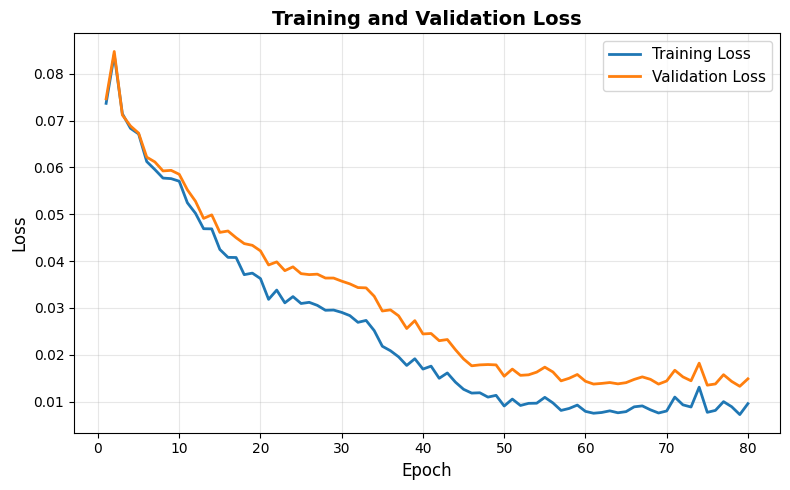

Saved: <repo>/results\Retrain_LGCN\LGCN_Loss_Curve.png
Final → Train loss: 0.0096 | Val loss: 0.0149 | Gap: 0.0053


In [10]:
# ═══════════════════════════════════════════════════════════════════
# CELL 8A — Training Loss Curve (MATCHED to Hybrid style — smooth lines)
# ═══════════════════════════════════════════════════════════════════

epochs_r   = [h['ep'] for h in history]
train_loss = [h['tl'] for h in history]
val_loss   = [h['vl'] for h in history]

plt.figure(figsize=(8, 5))
plt.plot(epochs_r, train_loss, label='Training Loss',
         linewidth=2, color='#1f77b4')
plt.plot(epochs_r, val_loss,   label='Validation Loss',
         linewidth=2, color='#ff7f0e')
plt.xlabel('Epoch',  fontsize=12)
plt.ylabel('Loss',   fontsize=12)
plt.title('Training and Validation Loss', fontsize=14, fontweight='bold')
plt.legend(fontsize=11, loc='upper right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
p = os.path.join(CONFIG['output_dir'], 'LGCN_Loss_Curve.png')
plt.savefig(p, dpi=600, bbox_inches='tight')
plt.show()
print(f'Saved: {p}')
print(f'Final → Train loss: {train_loss[-1]:.4f} | Val loss: {val_loss[-1]:.4f} | Gap: {abs(train_loss[-1]-val_loss[-1]):.4f}')


## Cell 8B — Training Accuracy Curve

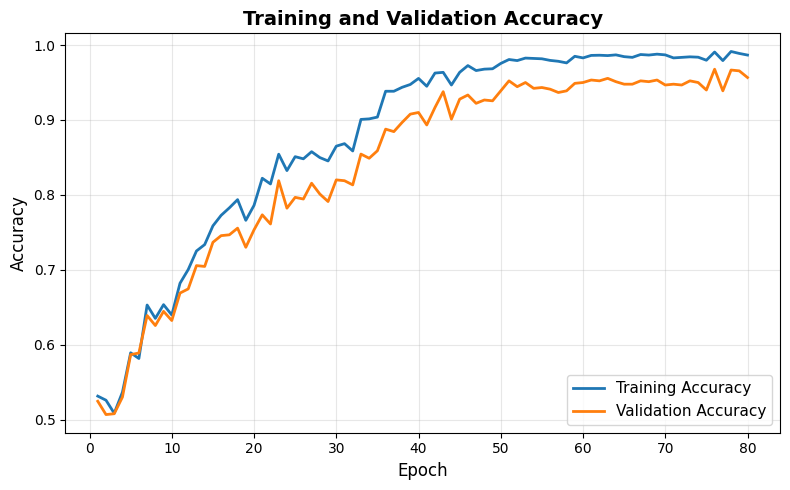

Saved: <repo>/results\Retrain_LGCN\LGCN_Accuracy_Curve.png
Train-Val gap: 0.0300 → Slight overfit (2-5%)


In [11]:
# ═══════════════════════════════════════════════════════════════════
# CELL 8B — Training Accuracy Curve (MATCHED to Hybrid style — smooth lines)
# ═══════════════════════════════════════════════════════════════════

train_acc = [h['ta'] for h in history]
val_acc   = [h['va'] for h in history]

plt.figure(figsize=(8, 5))
plt.plot(epochs_r, train_acc, label='Training Accuracy',
         linewidth=2, color='#1f77b4')
plt.plot(epochs_r, val_acc,   label='Validation Accuracy',
         linewidth=2, color='#ff7f0e')
plt.xlabel('Epoch',    fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.title('Training and Validation Accuracy', fontsize=14, fontweight='bold')
plt.legend(fontsize=11, loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
p = os.path.join(CONFIG['output_dir'], 'LGCN_Accuracy_Curve.png')
plt.savefig(p, dpi=600, bbox_inches='tight')
plt.show()
print(f'Saved: {p}')
gap = abs(train_acc[-1] - val_acc[-1])
print(f'Train-Val gap: {gap:.4f} → {"Good (<2%)" if gap<0.02 else "Slight overfit (2-5%)" if gap<0.05 else "Overfitting (>5%)"}')


## Cell 8C — Validation AUC Curve

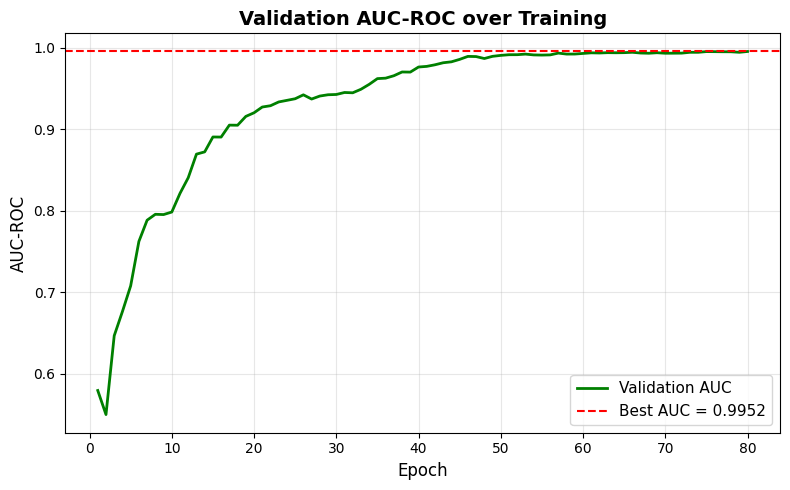

Saved: <repo>/results\Retrain_LGCN\LGCN_Validation_AUC_Curve.png
Best Val AUC: 0.9952


In [12]:
# ═══════════════════════════════════════════════════════════════════
# CELL 8C — Validation AUC Curve (MATCHED to Hybrid style — smooth lines)
# ═══════════════════════════════════════════════════════════════════

raw_auc     = [h['vauc'] for h in history]
val_auc_clean = [v if v > 0.5 else None for v in raw_auc]

# Sanitize: carry forward last valid value
def sanitize_curve(values):
    arr = list(values)
    first_valid = next((v for v in arr if v is not None and v > 0), 0.5)
    cleaned, last_good = [], first_valid
    for v in arr:
        if v is not None and v > 0:
            cleaned.append(v)
            last_good = v
        else:
            cleaned.append(last_good)
    return cleaned

val_auc_plot = sanitize_curve(raw_auc)
best_auc_val = max(val_auc_plot)

plt.figure(figsize=(8, 5))
plt.plot(epochs_r, val_auc_plot, color='green', linewidth=2,
         label='Validation AUC')
plt.axhline(y=best_auc_val, color='red', linestyle='--',
            label=f'Best AUC = {best_auc_val:.4f}')
plt.xlabel('Epoch',    fontsize=12)
plt.ylabel('AUC-ROC',  fontsize=12)
plt.title('Validation AUC-ROC over Training', fontsize=14, fontweight='bold')
plt.legend(fontsize=11, loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
p = os.path.join(CONFIG['output_dir'], 'LGCN_Validation_AUC_Curve.png')
plt.savefig(p, dpi=600, bbox_inches='tight')
plt.show()
print(f'Saved: {p}')
print(f'Best Val AUC: {best_auc_val:.4f}')


## Cell 8D — Confusion Matrix

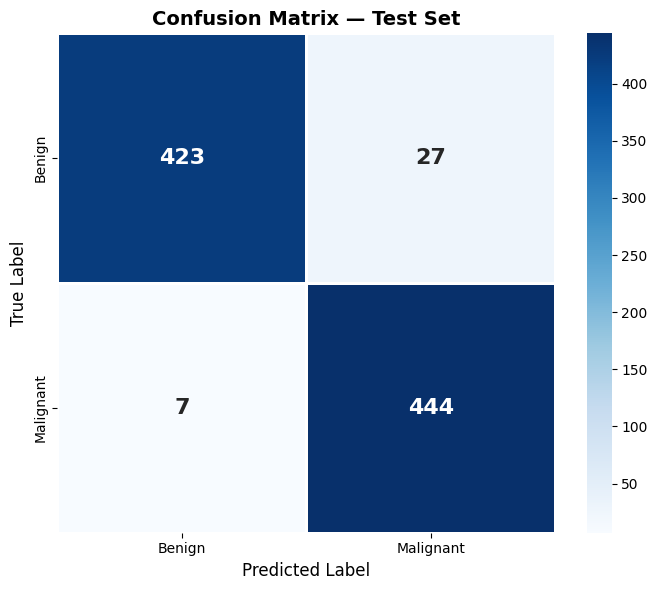

Saved: <repo>/results\Retrain_LGCN\LGCN_Confusion_Matrix.png

True Negatives  (Benign correct)    : 423
False Positives (Benign → Malignant) : 27
False Negatives (Malignant missed)   : 7
True Positives  (Malignant correct)  : 444

Sensitivity (Recall, Malignant) : 98.45%
Specificity (Recall, Benign)    : 94.00%
Precision (Malignant)           : 94.27%


In [13]:
# ═══════════════════════════════════════════════════════════════════
# CELL 8D — Confusion Matrix (MATCHED to Hybrid style)
# ═══════════════════════════════════════════════════════════════════

plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Benign', 'Malignant'],
            yticklabels=['Benign', 'Malignant'],
            cbar=True, annot_kws={'size': 16, 'weight': 'bold'},
            linewidths=1, linecolor='white')
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label',      fontsize=12)
plt.title('Confusion Matrix — Test Set', fontsize=14, fontweight='bold')
plt.tight_layout()
p = os.path.join(CONFIG['output_dir'], 'LGCN_Confusion_Matrix.png')
plt.savefig(p, dpi=600, bbox_inches='tight')
plt.show()
print(f'Saved: {p}')

tn, fp, fn, tp = cm.ravel()
print(f'\nTrue Negatives  (Benign correct)    : {tn}')
print(f'False Positives (Benign → Malignant) : {fp}')
print(f'False Negatives (Malignant missed)   : {fn}')
print(f'True Positives  (Malignant correct)  : {tp}')
print(f'\nSensitivity (Recall, Malignant) : {tp/(tp+fn)*100:.2f}%')
print(f'Specificity (Recall, Benign)    : {tn/(tn+fp)*100:.2f}%')
print(f'Precision (Malignant)           : {tp/(tp+fp)*100:.2f}%')


## Cell 8E — ROC Curve

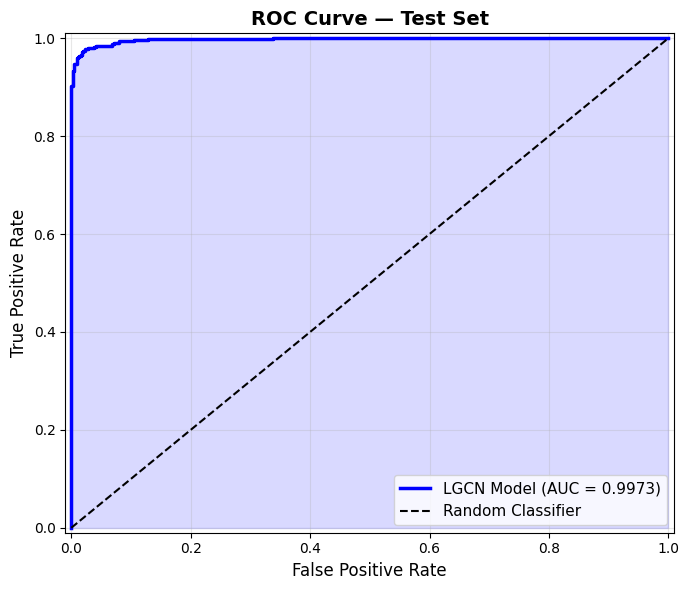

Saved: <repo>/results\Retrain_LGCN\LGCN_ROC_Curve.png


In [14]:
# ═══════════════════════════════════════════════════════════════════
# CELL 8E — ROC Curve (MATCHED to Hybrid style)
# ═══════════════════════════════════════════════════════════════════

fpr, tpr, _ = roc_curve(all_labels_test, all_probs_test)
roc_auc_val = auc(fpr, tpr)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, color='blue', linewidth=2.5,
         label=f'LGCN Model (AUC = {roc_auc_val:.4f})')
plt.fill_between(fpr, tpr, alpha=0.15, color='blue')
plt.plot([0, 1], [0, 1], color='black', linestyle='--', linewidth=1.5,
         label='Random Classifier')
plt.xlim([-0.01, 1.01])
plt.ylim([-0.01, 1.01])
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate',  fontsize=12)
plt.title('ROC Curve — Test Set', fontsize=14, fontweight='bold')
plt.legend(fontsize=11, loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
p = os.path.join(CONFIG['output_dir'], 'LGCN_ROC_Curve.png')
plt.savefig(p, dpi=600, bbox_inches='tight')
plt.show()
print(f'Saved: {p}')


## Cell 8F — Precision-Recall Curve

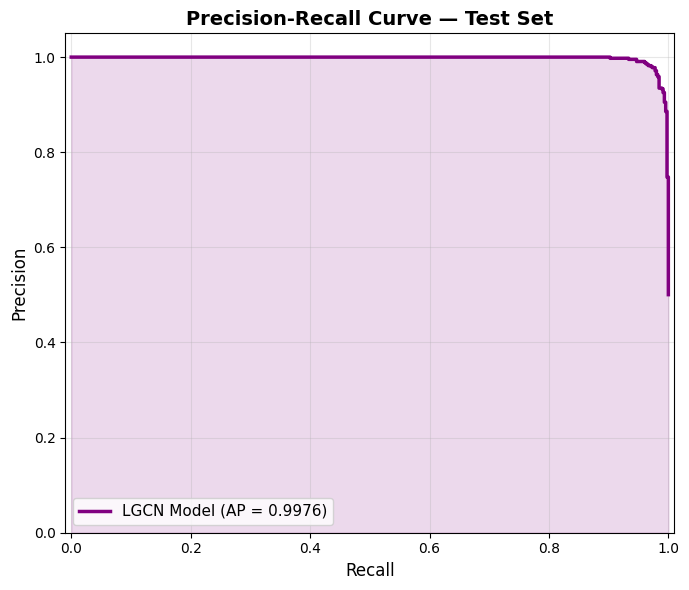

Saved: <repo>/results\Retrain_LGCN\LGCN_PR_Curve.png


In [15]:
# ═══════════════════════════════════════════════════════════════════
# CELL 8F — Precision-Recall Curve (MATCHED to Hybrid style)
# ═══════════════════════════════════════════════════════════════════

from sklearn.metrics import precision_recall_curve, average_precision_score

precision_arr, recall_arr, _ = precision_recall_curve(all_labels_test, all_probs_test)
avg_precision = average_precision_score(all_labels_test, all_probs_test)

plt.figure(figsize=(7, 6))
plt.plot(recall_arr, precision_arr, color='purple', linewidth=2.5,
         label=f'LGCN Model (AP = {avg_precision:.4f})')
plt.fill_between(recall_arr, precision_arr, alpha=0.15, color='purple')
plt.xlabel('Recall',    fontsize=12)
plt.ylabel('Precision', fontsize=12)
plt.title('Precision-Recall Curve — Test Set', fontsize=14, fontweight='bold')
plt.legend(fontsize=11, loc='lower left')
plt.grid(True, alpha=0.3)
plt.xlim([-0.01, 1.01])
plt.ylim([0, 1.05])
plt.tight_layout()
p = os.path.join(CONFIG['output_dir'], 'LGCN_PR_Curve.png')
plt.savefig(p, dpi=600, bbox_inches='tight')
plt.show()
print(f'Saved: {p}')


## Cell 8G — Sample Inference (Predicted Images with Green/Red Labels)

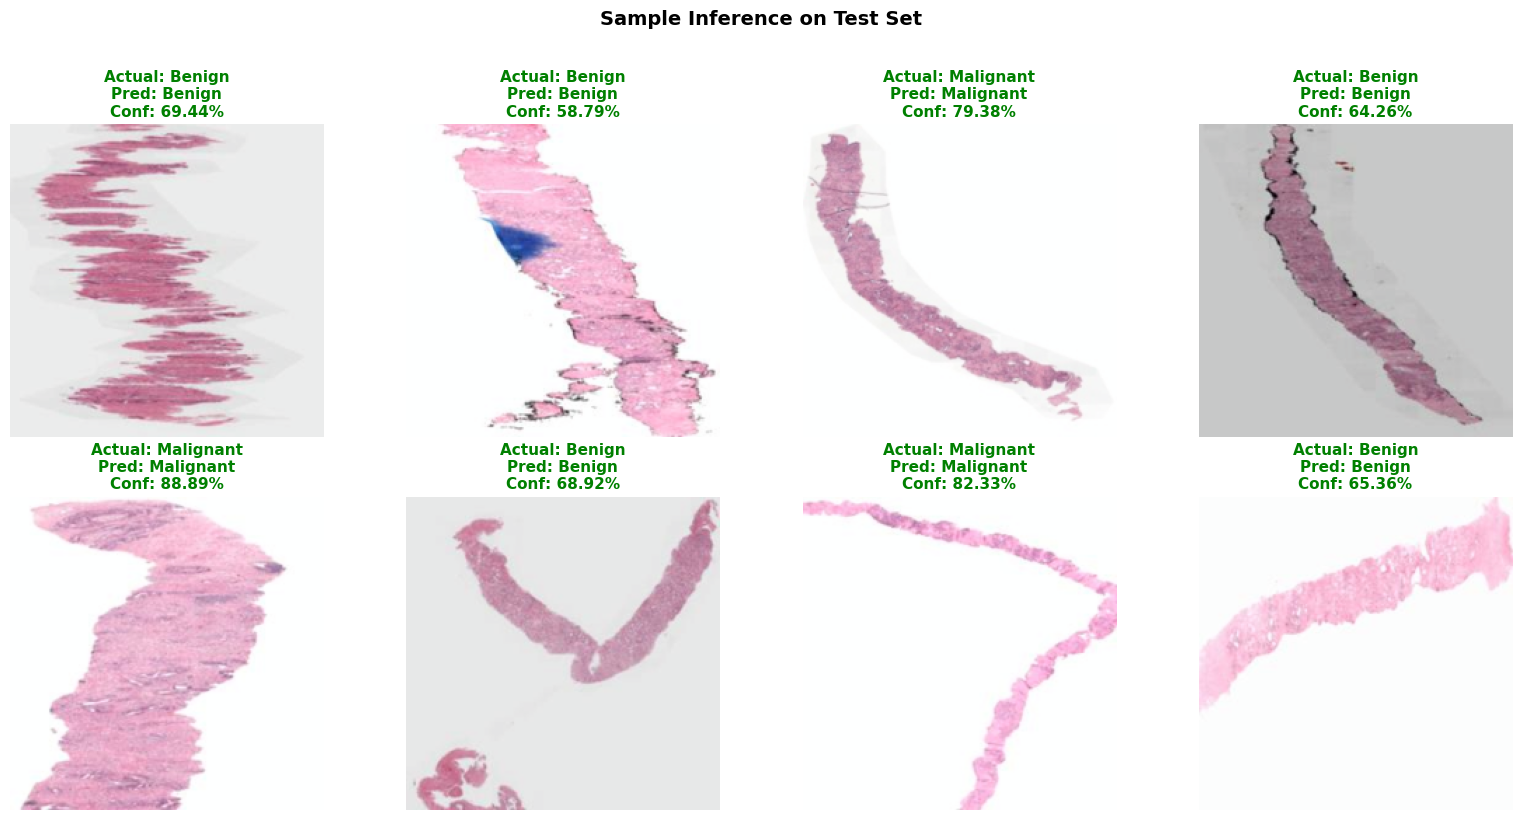


Visualized 8 random test samples
Saved to: <repo>/results\Retrain_LGCN\LGCN_Sample_Inference.png
Green title = correct prediction | Red title = incorrect


In [16]:
# ═══════════════════════════════════════════════════════════════════
# CELL 8G — Sample Inference (MATCHED to Hybrid style)
# ═══════════════════════════════════════════════════════════════════

CLASS_NAMES = ['Benign', 'Malignant']
class_names = CLASS_NAMES  # alias for edge detection cell

def predict_single(img_tensor, graph):
    model.eval()
    with torch.no_grad():
        g_batch = Batch.from_data_list([graph]).to(DEVICE)
        logits  = model(img_tensor.unsqueeze(0).to(DEVICE), g_batch)
        probs   = F.softmax(logits.float(), dim=1)[0].cpu().numpy()
    pred_idx = int(np.argmax(probs))
    return pred_idx, float(probs[pred_idx])

np.random.seed(42)
n_show = 8
sample_indices = np.random.choice(len(test_ds), n_show, replace=False)
indices = sample_indices  # alias for edge detection cell

plt.figure(figsize=(16, 8))

for i, idx in enumerate(sample_indices):
    img_t, graph, label = test_ds[idx]
    pred_idx, confidence = predict_single(img_t, graph)

    actual_class    = CLASS_NAMES[int(label)]
    predicted_class = CLASS_NAMES[pred_idx]
    is_correct      = (pred_idx == int(label))

    ax = plt.subplot(2, 4, i + 1)
    ax.imshow(denormalize(img_t))
    ax.axis('off')

    title_color = 'green' if is_correct else 'red'
    ax.set_title(
        f'Actual: {actual_class}\n'
        f'Pred: {predicted_class}\n'
        f'Conf: {confidence*100:.2f}%',
        fontsize=11,
        color=title_color,
        fontweight='bold'
    )

plt.suptitle('Sample Inference on Test Set',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
p = os.path.join(CONFIG['output_dir'], 'LGCN_Sample_Inference.png')
plt.savefig(p, dpi=600, bbox_inches='tight')
plt.show()

print(f'\nVisualized {n_show} random test samples')
print(f'Saved to: {p}')
print(f'Green title = correct prediction | Red title = incorrect')


## Cell 8H — Sobel Edge Detection on Sample Inference Images

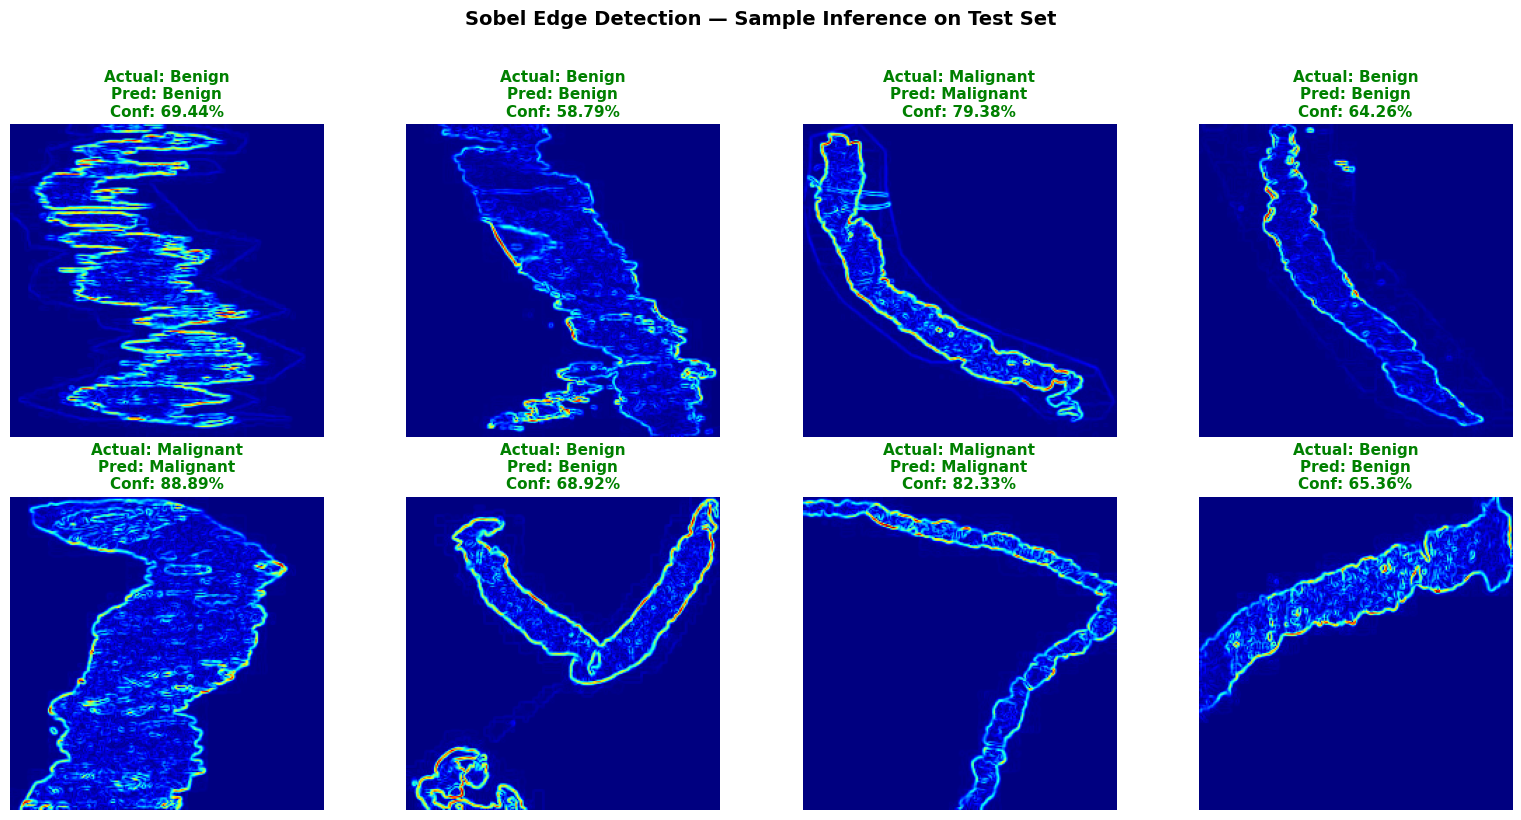


Sobel edge maps for 8 random test samples
Saved to: <repo>/results\Retrain_LGCN\LGCN_Sobel_Edge_Inference.png
Green title = correct prediction | Red title = incorrect


In [17]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 8H — Sobel Edge Detection on Sample Inference Images    ║
# ║ Shows edge maps for the same 8 test samples from Cell 8G     ║
# ║ Uses cv2.applyColorMap(COLORMAP_JET) — same as Hybrid 9K     ║
# ╚══════════════════════════════════════════════════════════════╝

plt.figure(figsize=(16, 8))

for i, idx in enumerate(sample_indices):   # reuses sample_indices from Cell 8G
    img_t, graph, label = test_ds[idx]

    pred_idx, confidence = predict_single(img_t, graph)

    actual_class    = CLASS_NAMES[int(label)]
    predicted_class = CLASS_NAMES[pred_idx]
    is_correct      = (pred_idx == int(label))

    # ── Denormalize → uint8 → grayscale → Sobel ────────────
    img_display = denormalize(img_t)
    img_uint8   = (img_display * 255).astype(np.uint8)
    img_gray    = cv2.cvtColor(img_uint8, cv2.COLOR_RGB2GRAY)

    sobel_x   = cv2.Sobel(img_gray, cv2.CV_64F, 1, 0, ksize=3)
    sobel_y   = cv2.Sobel(img_gray, cv2.CV_64F, 0, 1, ksize=3)
    magnitude = cv2.magnitude(sobel_x, sobel_y)
    mag_norm  = cv2.normalize(magnitude, None, 0, 255,
                              cv2.NORM_MINMAX, cv2.CV_8U)
    edges_bgr = cv2.applyColorMap(mag_norm, cv2.COLORMAP_JET)
    edges_rgb = cv2.cvtColor(edges_bgr, cv2.COLOR_BGR2RGB)

    ax = plt.subplot(2, 4, i + 1)
    ax.imshow(edges_rgb)
    ax.axis('off')

    title_color = 'green' if is_correct else 'red'
    ax.set_title(
        f'Actual: {actual_class}\n'
        f'Pred: {predicted_class}\n'
        f'Conf: {confidence*100:.2f}%',
        fontsize=11, color=title_color, fontweight='bold'
    )

plt.suptitle('Sobel Edge Detection — Sample Inference on Test Set',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
p = os.path.join(CONFIG['output_dir'], 'LGCN_Sobel_Edge_Inference.png')
plt.savefig(p, dpi=600, bbox_inches='tight')
plt.show()

print(f'\nSobel edge maps for {n_show} random test samples')
print(f'Saved to: {p}')
print(f'Green title = correct prediction | Red title = incorrect')


## Cell 8L — Canny Edge Detection on Sample Inference Images 

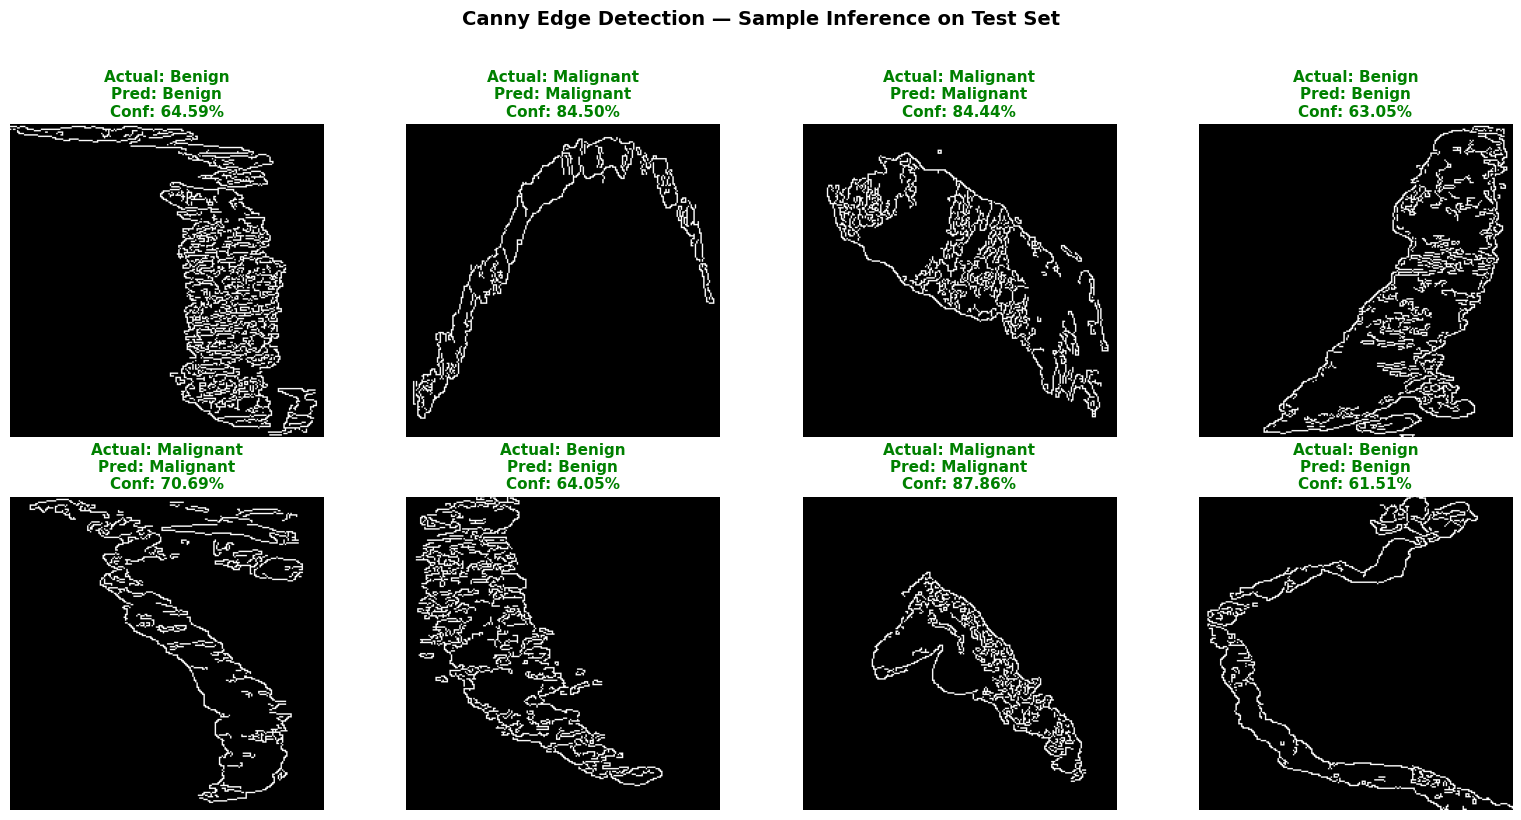


Canny edge maps for 8 random test samples
Saved to: Canny_Edge_Inference.png
Green title = correct prediction | Red title = incorrect


In [21]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 8L — Canny Edge Detection on Sample Inference Images    ║
# ║ Matched to Hybrid Cell 9J format                             ║
# ╚══════════════════════════════════════════════════════════════╝
class_names = ['Benign', 'Malignant']

n_show = 8
sample_idx = np.random.choice(len(all_labels_test), n_show, replace=False)

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for i, idx in enumerate(sample_idx):
    ax = axes[i // 4, i % 4]

    img_pil = Image.open(all_paths[test_idx][idx]).convert('RGB')
    img_np  = np.array(img_pil.resize((CONFIG['img_size'], CONFIG['img_size'])))
    gray    = cv2.cvtColor(img_np, cv2.COLOR_RGB2GRAY)
    edges   = cv2.Canny(gray, 50, 150)

    ax.imshow(edges, cmap='gray')
    ax.axis('off')

    actual_class    = class_names[all_labels_test[idx]]
    predicted_class = class_names[all_preds_test[idx]]
    confidence      = all_probs_test[idx] if all_preds_test[idx] == 1 \
                      else 1 - all_probs_test[idx]
    is_correct      = all_labels_test[idx] == all_preds_test[idx]

    title_color = 'green' if is_correct else 'red'
    ax.set_title(
        f'Actual: {actual_class}\n'
        f'Pred: {predicted_class}\n'
        f'Conf: {confidence*100:.2f}%',
        fontsize=11,
        color=title_color,
        fontweight='bold'
    )

plt.suptitle('Canny Edge Detection — Sample Inference on Test Set',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(WORK_DIR, 'Canny_Edge_Inference.png'),
            dpi=600, bbox_inches='tight')
plt.show()

print(f'\nCanny edge maps for {n_show} random test samples')
print(f'Saved to: Canny_Edge_Inference.png')
print(f'Green title = correct prediction | Red title = incorrect')


## Cell 8M - Morphological Operations 

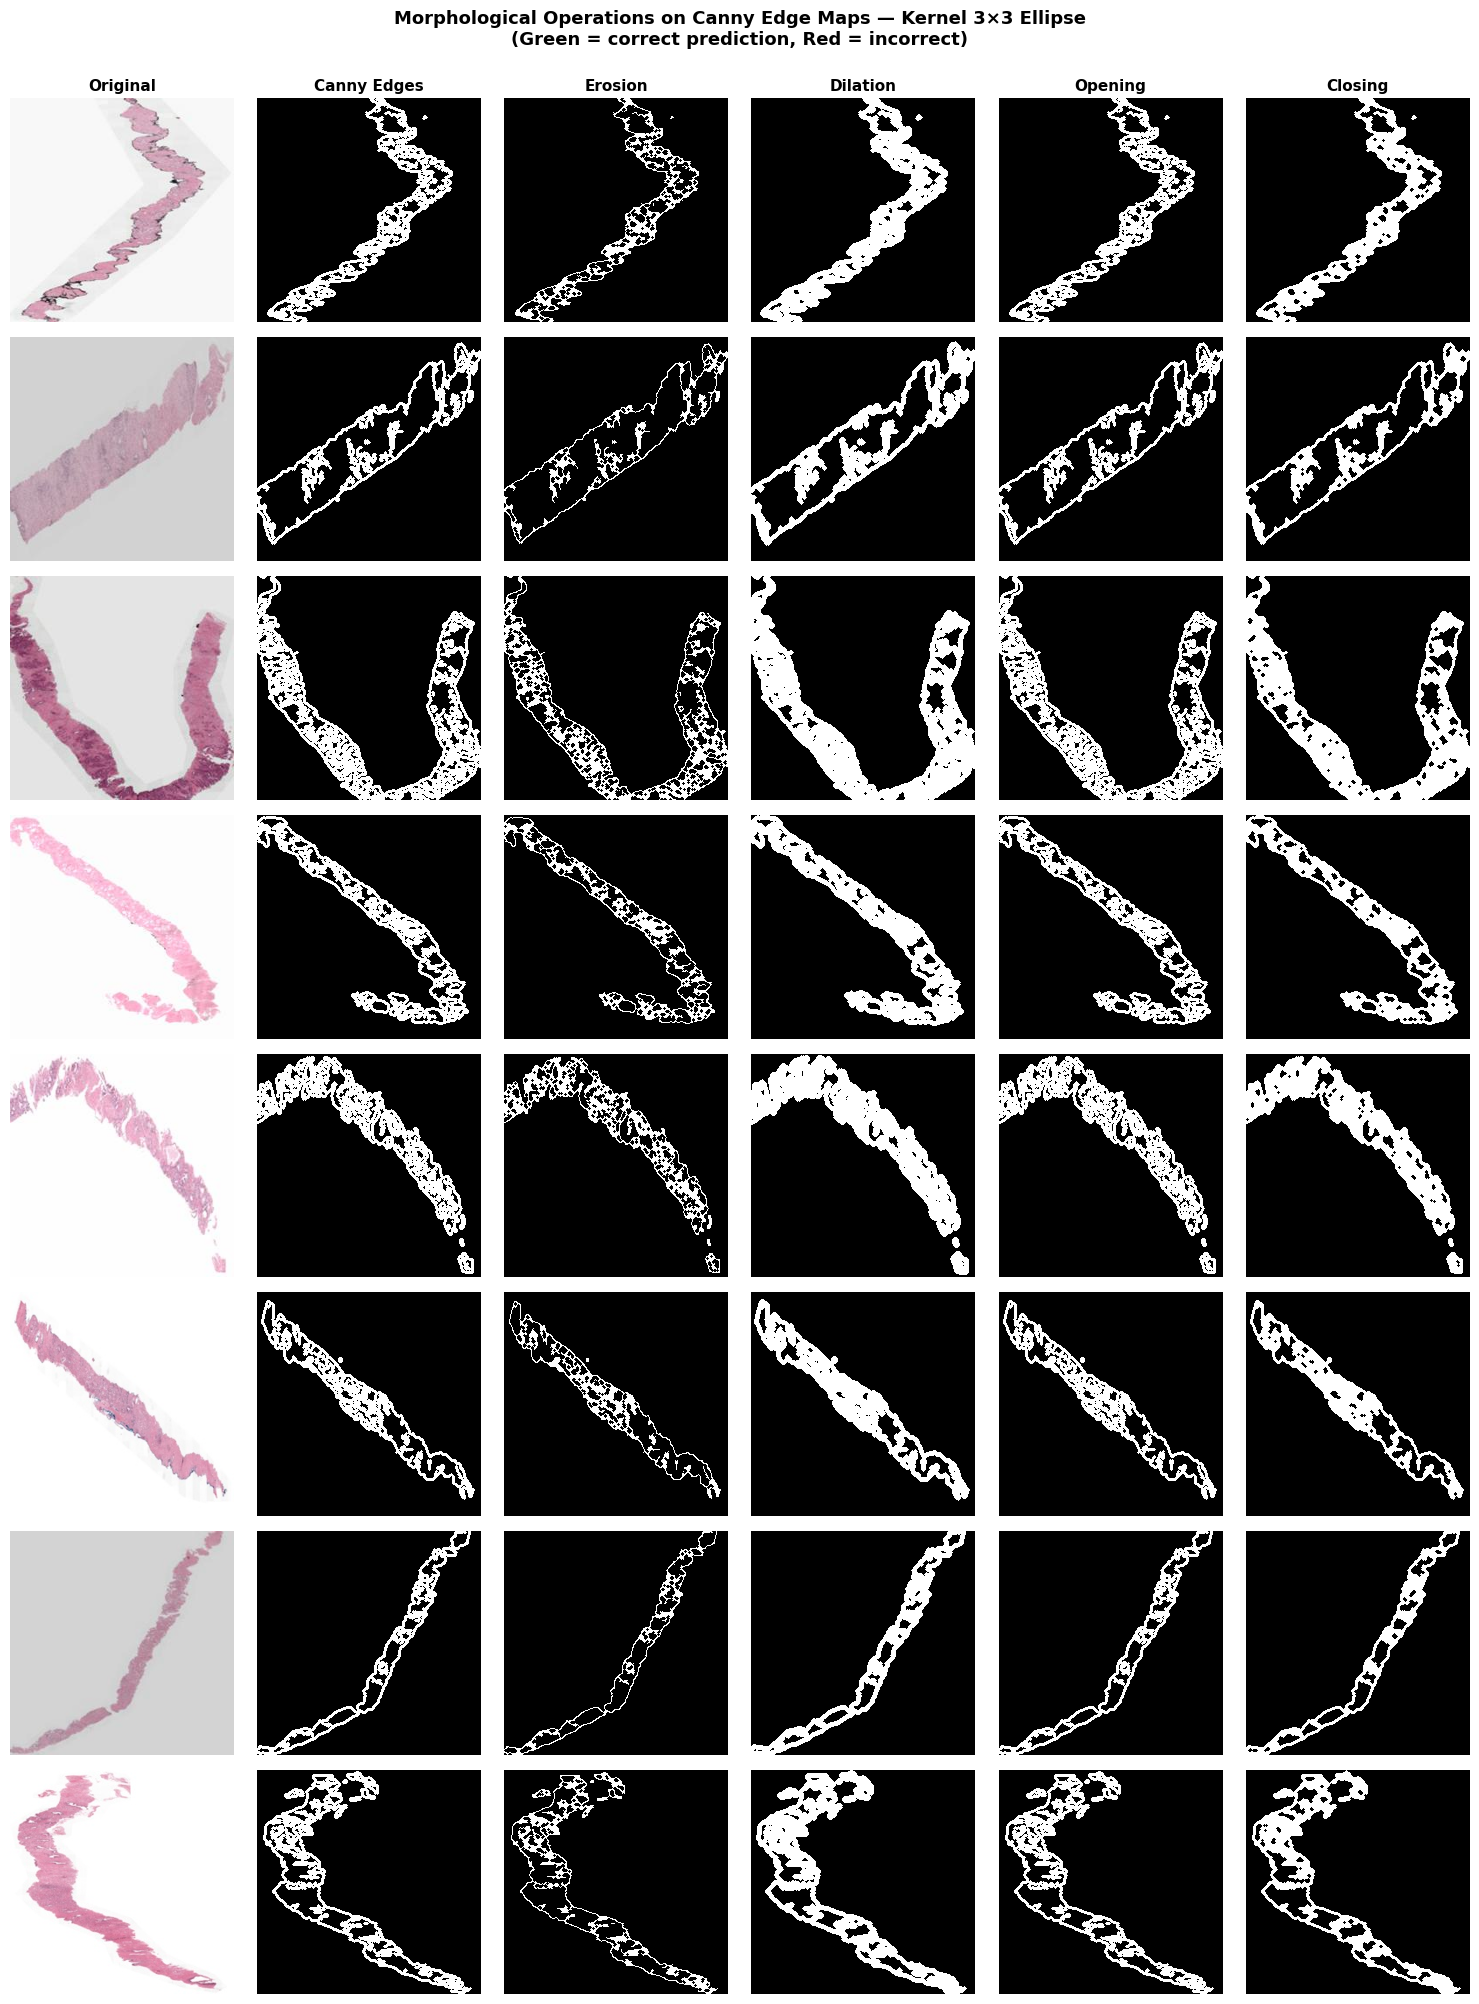


Saved to: Morphological_Canny.png


In [23]:
# ╔══════════════════════════════════════════════════════════════╗
# ║ CELL 8M — Morphological Operations on Canny Edge Maps        ║
# ║ Matched to Hybrid Cell 9L format                             ║
# ╚══════════════════════════════════════════════════════════════╝
class_names = ['Benign', 'Malignant']

n_show = 8
sample_idx = np.random.choice(len(all_labels_test), n_show, replace=False)
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))

col_titles = ['Original', 'Canny Edges', 'Erosion', 'Dilation', 'Opening', 'Closing']

fig, axes = plt.subplots(n_show, 6, figsize=(15, n_show*2.5))
for row, idx in enumerate(sample_idx):
    img_pil = Image.open(all_paths[test_idx][idx]).convert('RGB')
    img_np  = np.array(img_pil.resize((CONFIG['img_size'], CONFIG['img_size'])))
    gray    = cv2.cvtColor(img_np, cv2.COLOR_RGB2GRAY)

    canny_raw = cv2.Canny(gray, 30, 100)              # lower thresholds = denser edges
    canny     = cv2.dilate(canny_raw, kernel, iterations=1)  # thicken to match hybrid
    erosion   = cv2.erode(canny, kernel, iterations=1)
    dilation  = cv2.dilate(canny, kernel, iterations=1)
    opening   = cv2.morphologyEx(canny, cv2.MORPH_OPEN,  kernel)
    closing   = cv2.morphologyEx(canny, cv2.MORPH_CLOSE, kernel)

    axes[row, 0].imshow(img_np)
    axes[row, 1].imshow(canny,    cmap='gray')
    axes[row, 2].imshow(erosion,  cmap='gray')
    axes[row, 3].imshow(dilation, cmap='gray')
    axes[row, 4].imshow(opening,  cmap='gray')
    axes[row, 5].imshow(closing,  cmap='gray')

    # Column headers only on first row
    if row == 0:
        for c, t in enumerate(col_titles):
            axes[row, c].set_title(t, fontsize=11, fontweight='bold')

    for c in range(6):
        axes[row, c].axis('off')

    # Green/red side label showing correctness
    is_correct = all_labels_test[idx] == all_preds_test[idx]
    color = 'green' if is_correct else 'red'
    actual_class = class_names[all_labels_test[idx]]
    pred_class   = class_names[all_preds_test[idx]]
    axes[row, 0].set_ylabel(
        f'{actual_class} → {pred_class}',
        fontsize=9,
        color=color,
        fontweight='bold',
        rotation=0,
        labelpad=45,
        va='center'
    )

plt.suptitle(
    'Morphological Operations on Canny Edge Maps — Kernel 3×3 Ellipse\n'
    '(Green = correct prediction, Red = incorrect)',
    fontsize=13, fontweight='bold', y=1.00
)
plt.tight_layout()
plt.savefig(os.path.join(WORK_DIR, 'Morphological_Canny.png'),
            dpi=300, bbox_inches='tight')
plt.show()

print(f'\nSaved to: Morphological_Canny.png')

## Cell 8I — Final Performance Summary

In [20]:
# ═══════════════════════════════════════════════════════════════════
# CELL 8I — Final Performance Summary (MATCHED to Hybrid style)
# ═══════════════════════════════════════════════════════════════════

from sklearn.metrics import (accuracy_score, f1_score, recall_score,
                             precision_score, matthews_corrcoef,
                             classification_report)

print('═' * 60)
print('CLASSIFICATION REPORT — Test Set')
print('═' * 60)
print(classification_report(all_labels_test, all_preds_test,
                            target_names=['Benign', 'Malignant'],
                            digits=4))
print('═' * 60)

print(f"Accuracy    :  {acc:.4f}")
print(f"F1 Score    :  {f1:.4f}")
print(f"Recall      :  {rec:.4f}")
print(f"Precision   :  {prec:.4f}")
print(f"MCC         :  {mcc:.4f}")
print(f"AUC-ROC     :  {auc_sc:.4f}")
print(f"Sensitivity :  {sensitivity:.4f}")
print(f"Specificity :  {specificity:.4f}")

print('═' * 60)
print(f'Test Accuracy : {acc*100:.2f}%')
print(f'Test AUC-ROC  : {auc_sc:.4f}')
print('═' * 60)
print('\nAll plots saved as PNG (600 DPI) in:', CONFIG['output_dir'])
print('  • LGCN_Loss_Curve.png')
print('  • LGCN_Accuracy_Curve.png')
print('  • LGCN_Validation_AUC_Curve.png')
print('  • LGCN_Confusion_Matrix.png')
print('  • LGCN_ROC_Curve.png')
print('  • LGCN_PR_Curve.png')
print('  • LGCN_Sample_Inference.png')
print('  • LGCN_Sobel_Edge_Inference.png')


════════════════════════════════════════════════════════════
CLASSIFICATION REPORT — Test Set
════════════════════════════════════════════════════════════
              precision    recall  f1-score   support

      Benign     0.9837    0.9400    0.9614       450
   Malignant     0.9427    0.9845    0.9631       451

    accuracy                         0.9623       901
   macro avg     0.9632    0.9622    0.9622       901
weighted avg     0.9632    0.9623    0.9622       901

════════════════════════════════════════════════════════════
Accuracy    :  0.9623
F1 Score    :  0.9622
Recall      :  0.9623
Precision   :  0.9632
MCC         :  0.9254
AUC-ROC     :  0.9973
Sensitivity :  0.9845
Specificity :  0.9400
════════════════════════════════════════════════════════════
Test Accuracy : 96.23%
Test AUC-ROC  : 0.9973
════════════════════════════════════════════════════════════

All plots saved as PNG (600 DPI) in: <repo>/results\Retrain_LGCN
  • LGCN_Loss_Curve.png
  • LGCN_Accuracy_Curve